Business Understanding
        ↓
Data Collection
        ↓
Dataset Understanding
        ↓
Data Cleaning (Remove corrupted images)
        ↓
Train / Validation / Test Split
        ↓
Image Transformations
        ↓
Create Dataset (ImageFolder)
        ↓
Create DataLoaders
        ↓
Visualize Images
        ↓
Design CNN Architecture
        ↓
Choose Loss Function
        ↓
Choose Optimizer
        ↓
Training Loop
        ↓
Validation
        ↓
Hyperparameter Tuning (Optional)
        ↓
Model Evaluation
        ↓
Save Trained Model
        ↓
Inference / Prediction
        ↓
Deployment (Streamlit)
        ↓
GitHub + README

# imports

In [1]:
import torch
import torch.nn as nn
import os
import json
import numpy as np
import matplotlib.pyplot as plt

In [2]:
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch Version: 2.11.0+cu130
CUDA Available: True
Using Device: cuda
GPU: Tesla T4


2. Data Collection

In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
print(os.listdir("/content/drive/MyDrive"))

['Colab Notebooks', 'Shipsense', '"I am restarting my study journey after a 6.5-yea....gsheet', 'Google AI Studio', 'chest_xray_model_bht.pth', 'chest_xray_checkpoint_bht.pth', 'class_to_idx_bht.json', 'chest_xray_model_best.pth', 'new_chest_xray_model_bht.pth', 'new_chest_xray_checkpoint_bht.pth', 'new_class_to_idx_bht.json', 'Indian Food Images', 'indian_food_model_baseline.pth', 'indian_food_checkpoint_baseline.pth', 'indian_food_class_to_idx.json', 'Indian_Food_EfficientNet', 'kiaraadvanikapa.gdoc', 'face recogination']


In [5]:
!pip install -q kagglehub

In [6]:
import kagglehub

path = kagglehub.dataset_download("msambare/fer2013")
path

Using Colab cache for faster access to the 'fer2013' dataset.


'/kaggle/input/fer2013'

In [7]:
import os

print(os.listdir(path))

['test', 'train']


In [8]:
#count images

for folder in ["train", "test"]:
    folder_path = os.path.join(path, folder)

    if os.path.exists(folder_path):
        print(f"\n{folder.upper()}")

        for emotion in os.listdir(folder_path):
            emotion_path = os.path.join(folder_path, emotion)

            if os.path.isdir(emotion_path):
                print(emotion, ":", len(os.listdir(emotion_path)))


TRAIN
surprise : 3171
fear : 4097
angry : 3995
neutral : 4965
sad : 4830
disgust : 436
happy : 7215

TEST
surprise : 831
fear : 1024
angry : 958
neutral : 1233
sad : 1247
disgust : 111
happy : 1774


3. Dataset Understanding

We will inspect:

- Number of images in each class
- Total number of images
- Image dimensions
- Image channels
- File formats
- Sample images
- Class distribution

In [10]:
#lets first clarify all paths here

train_path = os.path.join(path, "train")
test_path = os.path.join(path, "test")

In [14]:
print(os.listdir(train_path))
print(os.listdir(test_path))
print(os.listdir(path))

['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy']
['surprise', 'fear', 'angry', 'neutral', 'sad', 'disgust', 'happy']
['test', 'train']


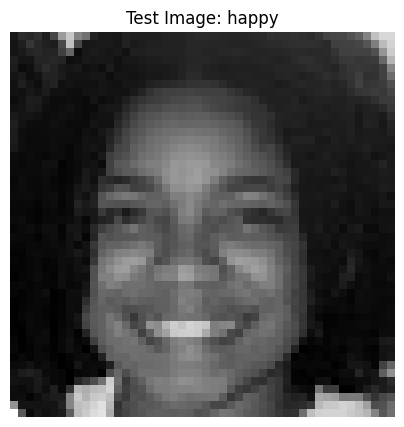

In [17]:
from PIL import Image

cls = "happy"
cls_path = os.path.join(test_path, cls)

files = os.listdir(cls_path)
sample_file = files[0]
img = Image.open(os.path.join(cls_path, sample_file))


plt.figure(figsize=(5, 5))
plt.imshow(img, cmap="gray")
plt.title(f"Test Image: {cls}")
plt.axis("off")
plt.show()

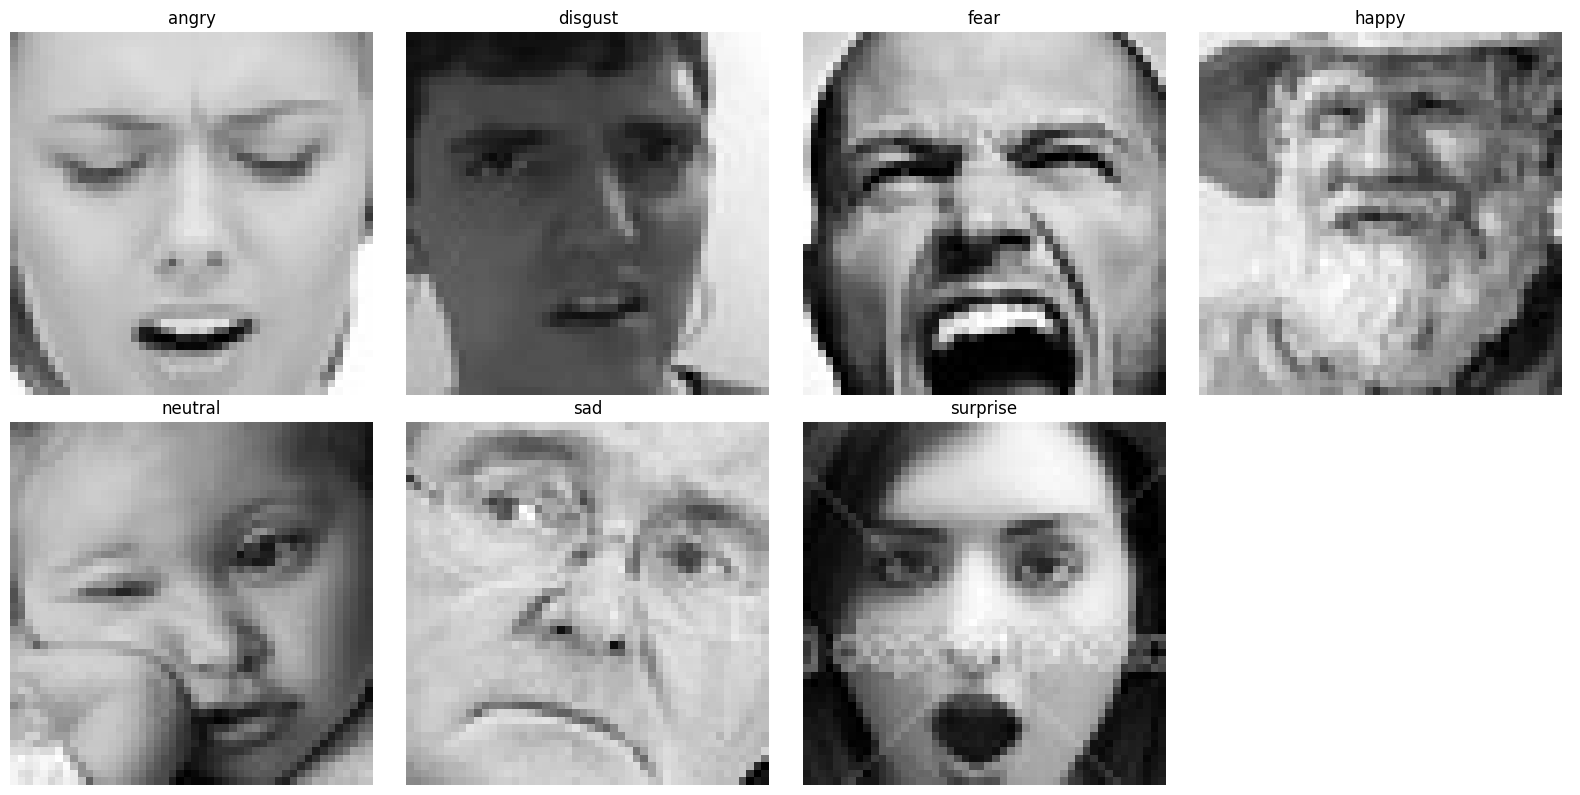

In [16]:
classes = sorted(os.listdir(train_path))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, cls in zip(axes.flatten(), classes):

    cls_path = os.path.join(train_path, cls)

    files = os.listdir(cls_path)

    if len(files) == 0:
        ax.set_title(f"{cls} (Empty)")
        ax.axis("off")
        continue

    sample_file = files[0]

    img = Image.open(os.path.join(cls_path, sample_file))

    ax.imshow(img, cmap="gray")
    ax.set_title(cls, fontsize=12)
    ax.axis("off")

# Hide unused subplot
for ax in axes.flatten()[len(classes):]:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    "/content/final_visualizing_sample_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# data clean


In [19]:
#scan for curropted imag

from PIL import Image, UnidentifiedImageError
corrupted_files = []

for split in ["train", "test"]:

    split_path = os.path.join(path, split)

    for cls in os.listdir(split_path):

        cls_path = os.path.join(split_path, cls)

        for fname in os.listdir(cls_path):

            fpath = os.path.join(cls_path, fname)

            try:
                with Image.open(fpath) as img:
                    img.verify()

            except (UnidentifiedImageError, OSError, SyntaxError):
                corrupted_files.append(fpath)

print("Corrupted images found:", len(corrupted_files))
print(corrupted_files)

Corrupted images found: 0
[]


In [20]:
#remove curropted image from files

#remove corrupted images

for fpath in corrupted_files:
    os.remove(fpath)

print("Removed", len(corrupted_files), "corrupted images")

Removed 0 corrupted images


#train / validation / test split and Image Transformation

Split ratio: 70% Train, 15% Validation, 15% Test.
Split is done on indices of the full ImageFolder dataset (random, seeded for reproducibility).

In [21]:
#our dataset is aready splited into train and test so we dont need to perform train test split from scratch the only thing we have to do is : create a validation folder


# Take Train folder make 20% of its as validation folder


# Step 1 — Load the training dataset

from torchvision import datasets, transforms

transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor()])








#now transform




full_train_dataset = datasets.ImageFolder(
    root=train_path,
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root=test_path,
    transform=transform
)

print("Training images:", len(full_train_dataset))
print("Testing images:", len(test_dataset))
print("Classes:", full_train_dataset.classes)




Training images: 28709
Testing images: 7178
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [22]:
# Step 2 — Split training data into train and validation

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset

# Get all image indices and their corresponding labels
indices = np.arange(len(full_train_dataset))
labels = full_train_dataset.targets





#split into 80% training and 20% validation

train_indices, val_indices = train_test_split(indices,test_size=0.2,random_state=42,stratify=labels)

train_dataset = Subset(full_train_dataset, train_indices)
val_dataset = Subset(full_train_dataset, val_indices)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

Training images: 22967
Validation images: 5742
Testing images: 7178


In [24]:
#lets first clarify all paths here

train_path = os.path.join(path, "train")
test_path = os.path.join(path, "test")
validation_path = os.path.join(path,"validation")

# Create DataLoaders

In [25]:
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [26]:
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))

# Check one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Train batches: 359
Validation batches: 90
Test batches: 113
Image batch shape: torch.Size([64, 1, 48, 48])
Label batch shape: torch.Size([64])


In [27]:
labels

tensor([2, 0, 6, 3, 5, 2, 0, 2, 2, 5, 2, 4, 3, 6, 5, 5, 2, 3, 3, 4, 2, 3, 5, 5,
        3, 6, 6, 4, 3, 0, 3, 6, 3, 5, 2, 4, 6, 3, 3, 4, 4, 0, 4, 2, 3, 2, 5, 2,
        3, 3, 2, 2, 5, 5, 5, 0, 5, 5, 0, 0, 0, 3, 2, 2])

In [29]:
#basic cnn archeitecture

class Facial(nn.Module):
    def __init__(self, num_classes):
        super(Facial, self).__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(256 * 14 * 14, 512)
        self.fc2 = nn.Linear(512, num_classes)

        self.dropout = nn.Dropout(0.4)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = self.pool(F.relu(self.conv4(x)))

        x = x.view(x.size(0), -1)

        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x

In [31]:
# Loss and Optimizer

num_classes = len(class_to_idx)

model = Facial(num_classes=num_classes).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Model device:", next(model.parameters()).device)

NameError: name 'class_to_idx' is not defined